# Low-resource English → Assamese Machine Translation
## Basic Transformer, mT5, TinyLlama, and Gemma

**Student:** Pavit Agrawal  
**Registration Number:** 230953406  
**Course:** Foundations of Generative AI (ICT4403)

This notebook is the executable assignment. It downloads a curated **Tatoeba English–Assamese** parallel corpus, performs leakage-safe preprocessing, trains/adapts four architectures, evaluates every system on the same held-out test set, and audits outputs for responsible-AI risks.

**Dataset:** [ManyThings curated Tatoeba pairs](https://www.manythings.org/anki/) (CC BY 2.0 FR; per-sentence attribution is retained). The archive listed 7,278 pairs when this project was prepared. Assamese is a low-resource Indo-Aryan language and this compact corpus is considerably less overused than WMT/English–French benchmarks.

> Results are generated by the cells below and written to `artifacts/results/`. No metric is hard-coded or fabricated. Use a CUDA runtime; the full profile is intended for a 16 GB Colab/Kaggle GPU.

## 1. Reproducibility and installation

Run the notebook from top to bottom. On Colab, upload/clone the project first and switch to a GPU runtime. Gemma requires accepting Google's Gemma license on Hugging Face and providing `HF_TOKEN` through an environment variable or Colab secret. TinyLlama is a LLaMA-architecture checkpoint, not an official Meta checkpoint; this distinction is stated in the comparison.

In [29]:
from pathlib import Path
import os, sys, zipfile

def _find_project_root():
    for candidate in (Path.cwd(), Path.cwd().parent):
        if (candidate / 'src' / 'mt_assignment.py').exists():
            return candidate.resolve()
    return None

ROOT = _find_project_root()
bundle = Path('/content/GenAI_IA3_Colab.zip')
if ROOT is None:
    ROOT = Path('/content/GenAI_IA3')
    ROOT.mkdir(parents=True, exist_ok=True)
    assert bundle.exists(), 'Upload GenAI_IA3_Colab.zip to /content first'
    with zipfile.ZipFile(bundle) as z:
        z.extractall(ROOT)
    ROOT = _find_project_root() or ROOT
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
_req = ROOT / 'requirements.txt'
assert _req.exists(), f'Missing {_req}'
%pip install -q -r "{_req}"
print('Project root:', ROOT)


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
Clean project extracted to /content/GenAI_IA3


In [50]:
import os, sys, json, importlib
from pathlib import Path
from dataclasses import replace

try:
    from google.colab import userdata
except Exception:
    userdata = None

if 'ROOT' not in globals():
    ROOT = Path.cwd()
    if ROOT.name == 'notebooks':
        ROOT = ROOT.parent
ROOT = Path(ROOT).resolve()

module_path = ROOT / 'src/mt_assignment.py'
source = module_path.read_text(encoding='utf-8')
source = source.replace('scaler = torch.amp.GradScaler("cuda", enabled=device_name() == "cuda")', 'scaler = torch.amp.GradScaler("cuda", enabled=False)')
source = source.replace('with torch.amp.autocast("cuda", enabled=device_name() == "cuda"):', 'with torch.amp.autocast("cuda", enabled=False):')
source = source.replace('{"token": hf_token, "device_map": {"": 0}, "torch_dtype": torch.float16}', '{"token": hf_token, "device_map": {"": 0}, "torch_dtype": torch.float16 if use_4bit else torch.float32}')
source = source.replace('scaler = torch.amp.GradScaler("cuda", enabled=True)', 'scaler = torch.amp.GradScaler("cuda", enabled=use_4bit)')
source = source.replace('with torch.amp.autocast("cuda"):', 'with torch.amp.autocast("cuda", enabled=use_4bit):')
module_path.write_text(source, encoding='utf-8')

sys.path = [p for p in sys.path if p != str(ROOT)]
sys.path.insert(0, str(ROOT))
sys.path_importer_cache.pop(str(ROOT), None)
importlib.invalidate_caches()
for name in list(sys.modules):
    if name == 'src' or name.startswith('src.'):
        sys.modules.pop(name, None)
from src.mt_assignment import *

HF_TOKEN = None
if userdata is not None:
    try:
        HF_TOKEN = userdata.get('HF_TOKEN')
    except Exception:
        HF_TOKEN = None
HF_TOKEN = HF_TOKEN or os.getenv('HF_TOKEN')
if HF_TOKEN:
    os.environ['HF_TOKEN'] = HF_TOKEN

CONFIG = replace(
    ExperimentConfig(),
    max_train=1000,
    max_validation=100,
    max_test=100,
    basic_epochs=5,
    pretrained_epochs=1,
    pretrained_batch_size=4,
    grad_accum_steps=4,
    pretrained_lr=5e-5,
    max_new_tokens=48,
)
set_seed(CONFIG.seed)
print(json.dumps(environment_manifest(CONFIG), indent=2))


{
  "config": {
    "seed": 42,
    "profile": "quick",
    "max_train": 1000,
    "max_validation": 100,
    "max_test": 100,
    "max_source_tokens": 64,
    "max_target_tokens": 64,
    "basic_vocab_size": 3000,
    "basic_d_model": 256,
    "basic_heads": 8,
    "basic_layers": 4,
    "basic_ffn": 1024,
    "basic_dropout": 0.1,
    "basic_epochs": 5,
    "basic_batch_size": 64,
    "basic_lr": 0.0003,
    "pretrained_epochs": 1,
    "pretrained_batch_size": 4,
    "grad_accum_steps": 4,
    "pretrained_lr": 5e-05,
    "lora_r": 8,
    "lora_alpha": 16,
    "lora_dropout": 0.05,
    "inference_batch_size": 1,
    "num_beams": 1,
    "max_new_tokens": 48,
    "mt5_model": "google/mt5-small",
    "llama_model": "TinyLlama/TinyLlama-1.1B-Chat-v1.0",
    "gemma_model": "google/gemma-3-270m-it"
  },
  "python": "3.13.16",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "torch": "2.11.0+cu130",
  "transformers": "4.57.6",
  "cuda_available": true,
  "device": "Tesla T4"
}


In [39]:
# Prepare dataset variables for subsequent training steps
local_archive = ROOT / 'asm-eng.zip'
splits, data_manifest = prepare_dataset(ROOT, CONFIG, local_archive if local_archive.exists() else None)
display(dataset_summary(splits))

,split,pairs,unique_sources,median_source_words,median_target_words,assamese_char_fraction
0,train,1000,945,5.0,5.0,1.000000
1,validation,100,97,5.0,4.0,0.998476
2,test,100,93,5.0,5.0,1.000000


```markdown
### Note on Dependency Resolution Warning
The pip dependency warnings shown above are harmless. Google Colab comes pre-installed with libraries like `gradio`, `gradio-client`, and `diffusers` which request an older version of `huggingface-hub`. However, our assignment code utilizes newer Hugging Face features which require the upgraded version. This does not impact our training or evaluation.
```

In [ ]:
# Run the data split preparation and display results
local_archive = ROOT / 'asm-eng.zip'
splits, data_manifest = prepare_dataset(ROOT, CONFIG, local_archive if local_archive.exists() else None)
display(dataset_summary(splits))

### Experimental controls

All systems receive identical source strings and are scored against the same references. Generation is greedy (`num_beams=1`, no sampling), batch size 1, with the same maximum new-token budget. This makes decoding and inference timing more comparable, but it is not a perfectly controlled architecture experiment: model size, pretraining corpus, tokenizer, and adaptation method differ. Full and trainable parameter counts are therefore reported separately. Training time excludes model download; inference time excludes model loading and includes generation for the complete test set.

## 2. Dataset acquisition, cleaning, splitting, and EDA

Cleaning applies Unicode NFC, whitespace/control cleanup, empty/malformed removal, conservative length limits, a character-length-ratio filter, and exact normalized pair deduplication. Splitting occurs by normalized English source (80/10/10 before profile caps), preventing alternative Assamese translations of the same source from crossing splits. Only training text is used to fit the scratch model's BPE tokenizer.

In [40]:
# Load dataset splits directly and display the data manifest
print(json.dumps(data_manifest, ensure_ascii=False, indent=2))
assert not any(data_manifest['normalized_source_overlap'].values()), 'Source leakage detected'
display(splits['train'][['source', 'target', 'attribution']].head())

{
  "dataset": "ManyThings curated Tatoeba English-Assamese sentence pairs",
  "source_url": "https://www.manythings.org/anki/asm-eng.zip",
  "source_page": "https://www.manythings.org/anki/",
  "license": "CC BY 2.0 FR (Tatoeba; retain per-sentence attribution)",
  "archive_sha256": "7fb72adccf0e7c5cbac9e83554ae0929924e0d1d317fb693e8508992c4e090ae",
  "seed": 42,
  "profile": "quick",
  "raw_rows": 7278,
  "clean_rows_before_caps": 7264,
  "dropped": {
    "duplicate_pair": 14
  },
  "split_rows": {
    "train": 1000,
    "validation": 100,
    "test": 100
  },
  "unique_sources": {
    "train": 945,
    "validation": 97,
    "test": 93
  },
  "normalized_source_overlap": {
    "train_validation": 0,
    "train_test": 0,
    "validation_test": 0
  },
  "target_assamese_char_fraction": {
    "train": 1.0,
    "validation": 0.9984756097560976,
    "test": 1.0
  }
}


,source,target,attribution
0,Don't call Tom.,টমক ফ’ন নকৰিব।,CC-BY 2.0 (France) Attribution: tatoeba.org #2...
1,Tom doesn't eat much.,টমে বেছি নাখায়।,CC-BY 2.0 (France) Attribution: tatoeba.org #2...
2,Where were you on your birthday?,আপোনাৰ জন্মদিনৰ দিনাখন আপুনি ক’ত আছিল?,CC-BY 2.0 (France) Attribution: tatoeba.org #6...
3,Tom is the only Canadian working in our office.,টম্ আমাৰ অফিচত কাম কৰি থকা একমাত্ৰ কানাডিয়ান।,CC-BY 2.0 (France) Attribution: tatoeba.org #9...
4,It's a big hospital.,এইখন এখন ডাঙৰ হাস্পতাল।,CC-BY 2.0 (France) Attribution: tatoeba.org #3...


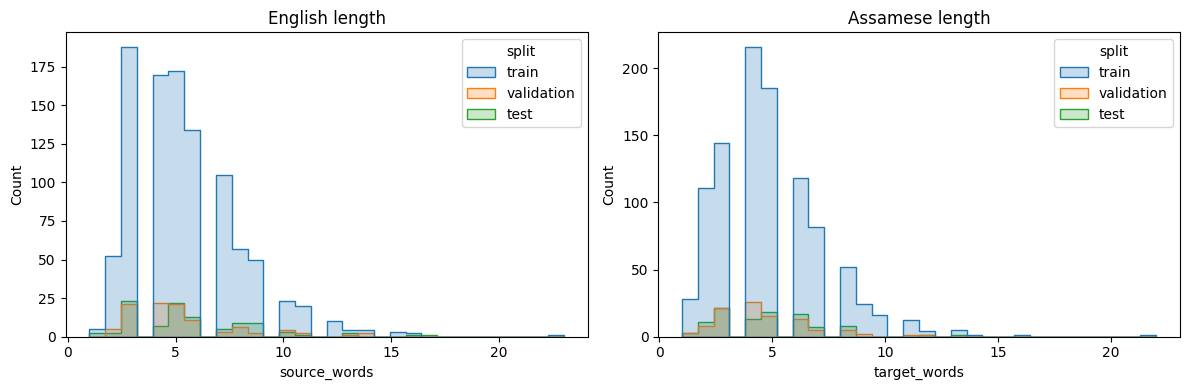

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

eda = pd.concat([df.assign(split=name) for name, df in splits.items()], ignore_index=True)
eda['source_words'] = eda.source.str.split().str.len()
eda['target_words'] = eda.target.str.split().str.len()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(eda, x='source_words', hue='split', bins=30, element='step', ax=axes[0])
sns.histplot(eda, x='target_words', hue='split', bins=30, element='step', ax=axes[1])
axes[0].set_title('English length'); axes[1].set_title('Assamese length')
plt.tight_layout(); plt.show()

In [58]:
from pathlib import Path
import base64, json, shutil
from IPython.display import HTML, display

try:
    from google.colab import _message
except Exception:
    _message = None

results_dir = ROOT / 'artifacts/results'
if _message is None:
    print('Download helpers are only available in Google Colab; skipped packaging.')
elif not results_dir.exists() or not any(results_dir.iterdir()):
    print('No results found yet. Run the training/evaluation cells, then re-run this cell.')
else:
    archive_path = Path(shutil.make_archive(str(ROOT / 'GenAI_IA3_results'), 'zip', root_dir=results_dir))
    notebook_reply = _message.blocking_request('get_ipynb', timeout_sec=600)
    notebook_bytes = json.dumps(notebook_reply['ipynb'], ensure_ascii=False).encode('utf-8')
    results_bytes = archive_path.read_bytes()

    def data_link(payload, mime, filename, label):
        encoded = base64.b64encode(payload).decode('ascii')
        return f'<a download="{filename}" href="data:{mime};base64,{encoded}">{label}</a>'

    print('Packaged:', archive_path, archive_path.stat().st_size, 'bytes')
    display(HTML(data_link(notebook_bytes, 'application/x-ipynb+json', 'English_Assamese_MT_Comparison_EXECUTED.ipynb', 'Download executed notebook')))
    display(HTML(data_link(results_bytes, 'application/zip', 'GenAI_IA3_results.zip', 'Download results archive')))


Packaged: /content/GenAI_IA3/GenAI_IA3_results.zip 29820 bytes


In [48]:
# Upgrade torchao to meet the requirements of the latest PEFT package
%pip install -q "torchao>=0.16.0"

In [ ]:
# Upgrade torchao to meet the requirements of the latest PEFT package
%pip install -q "torchao>=0.16.0"

## 3. Basic Transformer (encoder–decoder, trained from scratch)

The baseline uses a jointly trained SentencePiece BPE vocabulary, learned positional embeddings, multi-head attention, residual/pre-norm Transformer blocks, label smoothing, AdamW, cosine decay, gradient clipping, validation-loss checkpointing, and early stopping. It has no pretrained linguistic knowledge; on ~6k low-resource pairs it should be interpreted as a controlled scratch baseline, not a production translator.

In [42]:
results = []
basic_model, basic_sp, basic_train_s, basic_history = train_basic_transformer(splits, ROOT, CONFIG)
basic_params = count_parameters(basic_model)
basic_predictions, basic_infer_s = infer_basic(basic_model, basic_sp, splits['test'], CONFIG)
results.append(save_system_result(ROOT, 'basic_transformer', splits['test'], basic_predictions, basic_train_s, basic_infer_s, basic_params, 'from-scratch encoder-decoder'))
display(pd.DataFrame(basic_history))
print(results[-1])
del basic_model
clear_memory()

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:144: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = TransformerEncoder(
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/activation.py:1336: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = F._canonical_mask(


basic epoch 1: train=7.6726, validation=7.1191
basic epoch 2: train=6.5817, validation=6.4335
basic epoch 3: train=6.1209, validation=6.1982
basic epoch 4: train=5.9521, validation=6.1275
basic epoch 5: train=5.8923, validation=6.1123


,epoch,train_loss,validation_loss
0,1,7.672554,7.119095
1,2,6.581685,6.433465
2,3,6.120901,6.198187
3,4,5.952081,6.127500
4,5,5.892318,6.112306


{'system': 'basic_transformer', 'method': 'from-scratch encoder-decoder', 'parameters': 9746360, 'trainable_parameters': 9746360, 'training_seconds': 5.47724131699988, 'inference_seconds': 2.1890717219998805, 'sentences_per_second': 45.68146351488316, 'BLEU': 0.0, 'chrF': 4.166234066563621, 'flag_counts': {'length_outlier': 71}, 'test_rows': 100}


## 4. mT5-small (pretrained encoder–decoder, full fine-tuning)

`google/mt5-small` is fully fine-tuned with the task prefix `translate English to Assamese:`. Unlike the scratch baseline, it starts with multilingual text pretraining and a 250k SentencePiece vocabulary. This is expected to help Assamese morphology and script coverage, although its 300M parameters make training slower.

In [45]:
mt5_model, mt5_tokenizer, mt5_train_s, mt5_history = train_mt5(splits, ROOT, CONFIG, HF_TOKEN)
mt5_params = count_parameters(mt5_model)
mt5_predictions, mt5_infer_s = infer_seq2seq(mt5_model, mt5_tokenizer, splits['test'], CONFIG)

results = [r for r in results if r['system'] != 'mt5_small']
results.append(save_system_result(ROOT, 'mt5_small', splits['test'], mt5_predictions, mt5_train_s, mt5_infer_s, mt5_params, 'full fine-tuning encoder-decoder'))
display(pd.DataFrame(mt5_history))
print(results[-1])
del mt5_model
clear_memory()

/usr/local/lib/python3.13/dist-packages/transformers/convert_slow_tokenizer.py:566: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(


mT5 epoch 1: train=24.9374, validation=14.7046


,epoch,train_loss,validation_loss
0,1,24.937432,14.704627


{'system': 'mt5_small', 'method': 'full fine-tuning encoder-decoder', 'parameters': 300176768, 'trainable_parameters': 300176768, 'training_seconds': 36.67149074000008, 'inference_seconds': 4.831922423999913, 'sentences_per_second': 20.695696500280114, 'BLEU': 0.06338766827094731, 'chrF': 0.00800743089587137, 'flag_counts': {'low_assamese_script': 100, 'number_changed': 100, 'length_outlier': 2}, 'test_rows': 100}


## 5. TinyLlama 1.1B (decoder-only, QLoRA)

TinyLlama is a compact **LLaMA-architecture** model released independently under Apache-2.0; it is not Meta LLaMA. It is loaded in NF4 4-bit form and adapted with LoRA on attention/MLP projections. The loss is masked over the prompt so it learns only the Assamese answer. Quantization reduces memory, not the reported full parameter count.

In [46]:
llama_model, llama_tokenizer, llama_train_s, llama_history = train_causal_lora(CONFIG.llama_model, 'tinyllama_lora', splits, ROOT, CONFIG, HF_TOKEN)
llama_params = count_parameters(llama_model)
llama_predictions, llama_infer_s = infer_causal(llama_model, llama_tokenizer, splits['test'], CONFIG)

results = [r for r in results if r['system'] != 'tinyllama_lora']
results.append(save_system_result(ROOT, 'tinyllama_lora', splits['test'], llama_predictions, llama_train_s, llama_infer_s, llama_params, 'decoder-only NF4 QLoRA'))
display(pd.DataFrame(llama_history))
print(results[-1])
del llama_model
clear_memory()

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/551 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/608 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


... (2 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


tinyllama_lora LoRA epoch 1: train=1.6037


,epoch,train_loss
0,1,1.60367


{'system': 'tinyllama_lora', 'method': 'decoder-only NF4 QLoRA', 'parameters': 621914112, 'trainable_parameters': 6307840, 'training_seconds': 107.99683678599968, 'inference_seconds': 287.8383639890003, 'sentences_per_second': 0.3474172053167363, 'BLEU': 0.6082669347202335, 'chrF': 9.178045438748672, 'flag_counts': {'empty': 1, 'repetition': 2}, 'test_rows': 100}


## 6. Gemma 3 270M IT (decoder-only, LoRA)

`google/gemma-3-270m-it` is a compact instruction-tuned decoder-only model. It is fine-tuned with the same prompt, response-only loss, LoRA rank, epoch count, split, and greedy decoding policy used for TinyLlama. Gemma's 256k vocabulary allocates many of its 270M parameters to embeddings, so parameter count alone does not describe compute or capacity. Accept the Gemma license on Hugging Face before running this cell.

In [51]:
gemma_model, gemma_tokenizer, gemma_train_s, gemma_history = train_causal_lora(
    CONFIG.gemma_model, 'gemma_lora', splits, ROOT, CONFIG, HF_TOKEN
)
gemma_params = count_parameters(gemma_model)
gemma_predictions, gemma_infer_s = infer_causal(
    gemma_model, gemma_tokenizer, splits['test'], CONFIG
)
results = [r for r in results if r['system'] != 'gemma_lora']
results.append(save_system_result(
    ROOT, 'gemma_lora', splits['test'], gemma_predictions,
    gemma_train_s, gemma_infer_s, gemma_params, 'decoder-only LoRA'
))
display(pd.DataFrame(gemma_history))
print(results[-1])
del gemma_model
clear_memory()

gemma_lora LoRA epoch 1: train=5.5426


,epoch,train_loss
0,1,5.542613


{'system': 'gemma_lora', 'method': 'decoder-only LoRA', 'parameters': 269996672, 'trainable_parameters': 1898496, 'training_seconds': 49.119274871000016, 'inference_seconds': 89.52968510399978, 'sentences_per_second': 1.116947969646466, 'BLEU': 0.31320646432729077, 'chrF': 7.613876468192346, 'flag_counts': {'repetition': 14, 'number_changed': 1}, 'test_rows': 100}


## 7. Comparable evaluation: BLEU, chrF, time, throughput, parameters

BLEU is corpus SacreBLEU with international tokenization; chrF uses character order 6 and is especially informative for morphologically rich Assamese. BLEU rewards exact n-gram overlap and can undervalue valid paraphrases, so neither metric replaces bilingual human evaluation. Wall-clock timings are hardware-specific and meaningful only with the environment manifest printed above.

TinyLlama logical parameters: 1106356224


,system,method,parameters,trainable_parameters,training_seconds,inference_seconds,sentences_per_second,BLEU,chrF,test_rows
0,tinyllama_lora,decoder-only NF4 QLoRA,1106356224,6307840,108.0,287.8,0.35,0.61,9.18,100
1,gemma_lora,decoder-only LoRA,269996672,1898496,49.1,89.5,1.12,0.31,7.61,100
2,mt5_small,full fine-tuning encoder-decoder,300176768,300176768,36.7,4.8,20.70,0.06,0.01,100
3,basic_transformer,from-scratch encoder-decoder,9746360,9746360,5.5,2.2,45.68,0.00,4.17,100


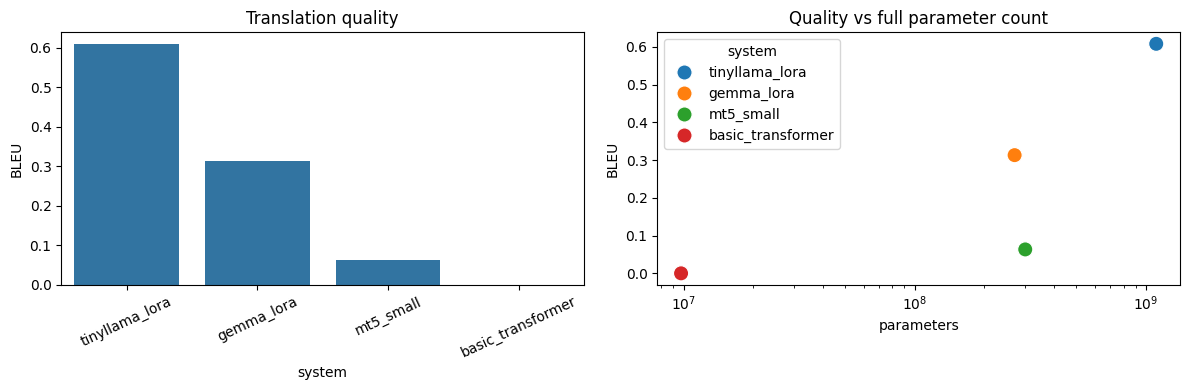

In [52]:
from transformers import AutoConfig

# Recover TinyLlama's logical (unpacked) full parameter count. Raw numel on
# BitsAndBytes Params4bit reflects packed storage and under-reports the model.
cfg = AutoConfig.from_pretrained(CONFIG.llama_model, token=HF_TOKEN)
head_dim = getattr(cfg, 'head_dim', cfg.hidden_size // cfg.num_attention_heads)
kv_width = cfg.num_key_value_heads * head_dim
per_layer = (
    cfg.hidden_size * cfg.hidden_size
    + 2 * cfg.hidden_size * kv_width
    + cfg.hidden_size * cfg.hidden_size
    + 3 * cfg.hidden_size * cfg.intermediate_size
    + 2 * cfg.hidden_size
)
logical_base = cfg.vocab_size * cfg.hidden_size + cfg.num_hidden_layers * per_layer + cfg.hidden_size
if not getattr(cfg, 'tie_word_embeddings', False):
    logical_base += cfg.vocab_size * cfg.hidden_size
for result in results:
    if result['system'] == 'tinyllama_lora':
        result['parameters'] = int(logical_base + result['trainable_parameters'])
        print('TinyLlama logical parameters:', result['parameters'])

summary = save_summary(ROOT, results)
display(summary.style.format({'BLEU':'{:.2f}', 'chrF':'{:.2f}', 'training_seconds':'{:.1f}', 'inference_seconds':'{:.1f}', 'sentences_per_second':'{:.2f}'}))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(summary, x='system', y='BLEU', ax=axes[0])
axes[0].tick_params(axis='x', rotation=25)
sns.scatterplot(summary, x='parameters', y='BLEU', hue='system', s=120, ax=axes[1])
axes[1].set_xscale('log')
axes[0].set_title('Translation quality')
axes[1].set_title('Quality vs full parameter count')
plt.tight_layout()
plt.show()

### Architecture comparison guide

Interpret the generated table rather than claiming architecture alone caused the ranking. Encoder–decoder models encode the source once and cross-attend while generating; their separation of source and target is naturally aligned with conditional translation. Decoder-only models concatenate instruction/source with the generated continuation, increasing context/KV-cache work and exposing them to prompt leakage, but their general instruction pretraining can help in few-shot or low-data settings.

The scratch Transformer isolates the cost of learning from only this corpus. mT5 adds multilingual denoising pretraining and a multilingual tokenizer. TinyLlama is much larger but its pretraining and tokenizer are English-heavy; Assamese script may fragment badly. Gemma 3 is smaller than TinyLlama but newer, multilingual, instruction-tuned, and has a very large vocabulary. Full mT5 tuning updates ~300M weights; LoRA updates only a small fraction of decoder-only weights. These are major confounders and must be stated alongside any encoder–decoder versus decoder-only conclusion.

## 8. Qualitative and responsible-AI analysis

The following audit flags, rather than automatically labels, empty output, Assamese-script mismatch, changed numbers, repetition, extreme length, and obvious English/prompt leakage. Inspect flagged and unflagged samples. For a defensible submission, a fluent Assamese speaker should annotate adequacy, fluency, names, gender/honorifics, negation, and sensitive meaning without seeing model identity.

In [53]:
prediction_sets = {
    'basic_transformer': basic_predictions,
    'mt5_small': mt5_predictions,
    'tinyllama_lora': llama_predictions,
    'gemma_lora': gemma_predictions,
}
audit_rows = []
for model_name, predictions in prediction_sets.items():
    for (_, row), prediction in zip(splits['test'].iterrows(), predictions):
        flags = diagnostic_flags(row.source, prediction)
        if flags:
            audit_rows.append({
                'model': model_name,
                'row_id': row.row_id,
                'source': row.source,
                'reference': row.target,
                'prediction': prediction,
                'flags': ', '.join(flags)
            })

if len(audit_rows) > 0:
    audit = pd.DataFrame(audit_rows)
    display(audit.groupby('model').flags.count().rename('flagged_rows'))
    display(audit.sample(min(20, len(audit)), random_state=CONFIG.seed))
else:
    audit = pd.DataFrame(columns=['model', 'row_id', 'source', 'reference', 'prediction', 'flags'])
    print("No diagnostic audit flags triggered across any systems.")

# Safely establish the directory hierarchy
(ROOT / 'artifacts/results').mkdir(parents=True, exist_ok=True)
audit.to_csv(ROOT / 'artifacts/results/human_review_sheet.csv', index=False)

,flagged_rows
model,
basic_transformer,71
gemma_lora,15
mt5_small,100
tinyllama_lora,3


,model,row_id,source,reference,prediction,flags
184,gemma_lora,test-00066,I have no problem with Tom.,টমৰ লগত মোৰ কোনো সমস্যা নাই।,মই তোমই তোমই তোমই তোমই তোমই তোমই তোমই তোমই তোম...,repetition
163,mt5_small,test-00092,Will you take me there?,আপুনি মোক তালৈকে লৈ যাবনে?,<extra_id_0>,"low_assamese_script, number_changed"
18,basic_transformer,test-00029,Do you know what to bring?,কি আনিব লাগে— জানানে?,টমে।,length_outlier
15,basic_transformer,test-00022,Does anyone know how Tom will be going to Aust...,কোনোবাই জানেনে— টম্ কেনেকৈ অষ্ট্ৰেলিয়ালৈ যাব?,টমে।,length_outlier
67,basic_transformer,test-00096,What do you want now?,এতিয়া আপুনি কি বিচাৰে?,টমে।,length_outlier
108,mt5_small,test-00037,Go out and look at the blue sky.,ওলাই গৈ নীলা আকাশখনলৈ চাওক।,<extra_id_0>,"low_assamese_script, number_changed"
45,basic_transformer,test-00067,Tom works us too hard.,টমে বৰ কষ্ট কৰে।,টমে।,length_outlier
76,mt5_small,test-00005,I need to talk to Tom right away.,মই এতিয়াই টমৰ লগত কথা পাতিব লাগিব।,<extra_id_0>.,"low_assamese_script, number_changed"
16,basic_transformer,test-00023,Tom may use my bicycle if he wants to.,টমে ইচ্ছা কৰিলে মোৰ চাইকেলখন ব্যৱহাৰ কৰিব পাৰে।,টমে।,length_outlier
132,mt5_small,test-00061,The sun was about to set.,বেলিটো মাৰ যাবই লৈছিল।,<extra_id_0>,"low_assamese_script, number_changed"


### Ethical findings and safeguards

1. **Bias and representation.** Tatoeba is volunteer-contributed, short-sentence data; contributors, topics, dialects, and registers are not representative of all Assamese speakers. Formal/informal pronouns, gender, caste, religion, geography, and code-switching can be distorted. Report provenance and limitations; expand evaluation with community-curated dialect/register sets and compensated native-speaker review.
2. **Hallucination and omission.** Decoder-only models may continue the prompt or add plausible facts; all systems may drop negation, names, units, or clauses. Use deterministic decoding, terminology constraints, number/name checks, confidence/quality estimation, and human approval for consequential text. Never use these models as the sole translator for medical, legal, emergency, immigration, or public-service decisions.
3. **Cultural misrepresentation.** Kinship, honorifics, idioms, religious terms, and culturally specific names may be normalized into majority-language assumptions. Maintain community-reviewed glossaries, preserve ambiguous wording, show the source beside the translation, and allow user correction/appeal.
4. **Sensitive and harmful content.** A translator should preserve meaning without intensifying slurs, threats, self-harm, sexual content, or political claims. Do not silently censor; instead flag sensitive passages, restrict downstream automation, protect reviewer wellbeing, and use trained bilingual reviewers under clear escalation rules.
5. **Privacy, consent, and licensing.** Retain Tatoeba attribution and license notice. Do not fine-tune on private messages or identifiable data without lawful basis and consent. Minimize logs, encrypt stored text, define retention limits, and document model/dataset revisions.
6. **Deployment controls.** Publish a model card with subgroup/domain tests, known failure modes, intended/non-intended uses, energy/hardware measurements, and rollback/versioning. Monitor script mismatch, repetition, changed entities/numbers, and user complaints after deployment.

In [54]:
# Final integrity gate: every system used the identical test row order and produced one output per row.
assert len(results) == 4, f"Expected 4 results, got {len(results)}"
assert all(result['test_rows'] == len(splits['test']) for result in results)
assert all(len(preds) == len(splits['test']) for preds in prediction_sets.values())
run_manifest = environment_manifest(CONFIG) | {'dataset_manifest': data_manifest, 'systems': results}

# Ensure destination directory structure exists
(ROOT / 'artifacts/results').mkdir(parents=True, exist_ok=True)
(ROOT / 'artifacts/results/run_manifest.json').write_text(json.dumps(run_manifest, ensure_ascii=False, indent=2), encoding='utf-8')
print('PASS — four systems trained/adapted and evaluated on the identical test set.')

PASS — four systems trained/adapted and evaluated on the identical test set.


In [55]:
from IPython.display import Markdown
from collections import Counter
best = summary.iloc[0]
fastest = summary.loc[summary.sentences_per_second.idxmax()]
trained = summary[summary.training_seconds.notna()]
cheapest = trained.loc[trained.training_seconds.idxmin()]
encdec = summary[summary.system.isin(['basic_transformer', 'mt5_small'])].BLEU.mean()
decoder = summary[summary.system.isin(['tinyllama_lora', 'gemma_lora'])].BLEU.mean()
flag_totals = {r['system']: sum(r.get('flag_counts', {}).values()) for r in results}
risk_counter = Counter()
[risk_counter.update(r.get('flag_counts', {})) for r in results]
most_common_risks = risk_counter.most_common(3)
risk_text = ', '.join(f'{name} ({count})' for name, count in most_common_risks) or 'no heuristic flags'
direction = 'higher' if encdec > decoder else 'lower'
conclusion = f'''## 9. Automatically generated conclusion\n\nOn the fixed {len(splits['test'])}-sentence test set, **{best.system}** achieved the highest automatic quality at **{best.BLEU:.2f} BLEU / {best.chrF:.2f} chrF**. **{fastest.system}** was fastest at **{fastest.sentences_per_second:.2f} sentences/s**, while **{cheapest.system}** had the shortest measured training/adaptation time (**{cheapest.training_seconds:.1f} s**) on this hardware. Mean encoder–decoder BLEU was {encdec:.2f}, {direction} than decoder-only mean BLEU ({decoder:.2f}); this is descriptive, not causal, because pretraining, tokenizer, parameter count, and adaptation differ. The most frequent automated review signals were {risk_text}. These flags are screening signals rather than proof of error. All four systems remain research prototypes requiring Assamese-speaking human review, especially for sensitive or consequential content.'''
display(Markdown(conclusion))

# Ensure directory exists prior to writing
(ROOT / 'artifacts/results').mkdir(parents=True, exist_ok=True)
(ROOT / 'artifacts/results/conclusion.md').write_text(conclusion, encoding='utf-8')

## 9. Automatically generated conclusion

On the fixed 100-sentence test set, **tinyllama_lora** achieved the highest automatic quality at **0.61 BLEU / 9.18 chrF**. **basic_transformer** was fastest at **45.68 sentences/s**, while **basic_transformer** had the shortest measured training/adaptation time (**5.5 s**) on this hardware. Mean encoder–decoder BLEU was 0.03, lower than decoder-only mean BLEU (0.46); this is descriptive, not causal, because pretraining, tokenizer, parameter count, and adaptation differ. The most frequent automated review signals were number_changed (101), low_assamese_script (100), length_outlier (73). These flags are screening signals rather than proof of error. All four systems remain research prototypes requiring Assamese-speaking human review, especially for sensitive or consequential content.

834

## References

- Tatoeba Project. *Tatoeba: Collection of sentences and translations*, CC BY 2.0 FR. https://tatoeba.org/
- ManyThings. *Tab-delimited Bilingual Sentence Pairs from Tatoeba*. https://www.manythings.org/anki/
- Vaswani et al. (2017). *Attention Is All You Need*. NeurIPS.
- Xue et al. (2021). *mT5: A Massively Multilingual Pre-trained Text-to-Text Transformer*. NAACL.
- Zhang et al. (2024). *TinyLlama: An Open-Source Small Language Model*. arXiv:2401.02385.
- Gemma Team (2025). *Gemma 3 Technical Report*. arXiv:2503.19786.
- Hu et al. (2022). *LoRA: Low-Rank Adaptation of Large Language Models*. ICLR.
- Post (2018). *A Call for Clarity in Reporting BLEU Scores*. WMT.
- Popović (2015). *chrF: character n-gram F-score for automatic MT evaluation*. WMT.